# Gas and Electricity Consumption Data Cleaning and EDA

Each instances represents a property, with information about its characteristics, energy consumption, and energy-related improvements.

---

## Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

## Define project folders, configure visualisations

In [4]:
from pathlib import Path

# --- Folders --------------------------------------------------------------
DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

In [5]:
# Check whether the dataset exists locally
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

DATA_PATH = DATA_DIR / "anon2026_50k.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {df.shape}")

Dataset loaded successfully: (50000, 96)


Initial 5 rows of the dataset

In [6]:
df.head()

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.00,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1,"6,600.00","6,600.00","5,500.00","6,600.00","7,400.00","7,400.00","9,600.00","9,600.00","6,700.00",...,"1,000.00",NaN,"1,600.00","2,300.00","2,200.00",V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.00,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1,"13,500.00","14,100.00","12,500.00","13,900.00","16,900.00","17,000.00","15,100.00","16,500.00","17,400.00",...,"4,500.00","4,100.00","4,500.00","4,800.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.00,E,3.00,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1,"9,700.00","7,100.00","7,100.00","10,100.00",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.00,C,4.00,NaN,E12000004,A/B,0,NaN,0,NaN,0,NaN,1,"5,700.00","5,200.00","5,300.00","5,300.00","10,500.00",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.00,NaN,E12000008,D,1,"2,006.00",0,NaN,0,NaN,1,"11,500.00","11,500.00","12,000.00","14,400.00","13,700.00","14,300.00","14,000.00","13,700.00","13,200.00",...,"3,500.00","3,800.00","3,300.00","3,700.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V


# Initial Data checking and removing duplicates

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 96 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PROP_TYPE          50000 non-null  str    
 1   PROP_AGE_BAND      50000 non-null  int64  
 2   FLOOR_AREA_BAND    50000 non-null  int64  
 3   CONSERVATORY_FLAG  9539 non-null   float64
 4   COUNCIL_TAX_BAND   50000 non-null  str    
 5   IMD_BAND_ENG       47578 non-null  float64
 6   IMD_BAND_WALES     2422 non-null   float64
 7   REGION             50000 non-null  str    
 8   EPC                50000 non-null  str    
 9   LI_FLAG            50000 non-null  int64  
 10  LI_DATE            7180 non-null   float64
 11  CWI_FLAG           50000 non-null  int64  
 12  CWI_DATE           7164 non-null   float64
 13  PV_FLAG            50000 non-null  int64  
 14  PV_DATE            800 non-null    float64
 15  MAIN_HEAT_FUEL     50000 non-null  int64  
 16  Gcons2024          39502 non-null

In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PROP_TYPE,50000,6,Semi detached,12592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PROP_AGE_BAND,"50,000.00",NaN,NaN,NaN,2.34,1.04,1.00,2.00,2.00,3.00,4.00
FLOOR_AREA_BAND,"50,000.00",NaN,NaN,NaN,2.29,0.91,1.00,2.00,2.00,3.00,5.00
CONSERVATORY_FLAG,"9,539.00",NaN,NaN,NaN,0.12,0.33,0.00,0.00,0.00,0.00,1.00
COUNCIL_TAX_BAND,50000,9,A,11539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
ElecValFlag2009,49230,5,V,40793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2008,49230,5,V,40179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2007,49230,5,V,39781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2006,49230,5,V,39796,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df_clean = df.copy()

In [10]:
n_duplicates = df_clean.duplicated().sum()   # True counts as 1, False as 0
print(f"Exact duplicated rows: {n_duplicates:,}")

Exact duplicated rows: 2


In [11]:
duplicates = df_clean[df_clean.duplicated(keep=False)]

display(duplicates)

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
3238,Flat,4,1,0.00,A,1.00,NaN,E12000002,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
9334,Flat,4,1,0.00,A,1.00,NaN,E12000002,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
10461,Flat,4,1,0.00,C,2.00,NaN,E12000007,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
16923,Flat,4,1,0.00,C,2.00,NaN,E12000007,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O


In [12]:
df_clean = df_clean.drop_duplicates().copy()

print("Remaining rows:", len(df_clean))

Remaining rows: 49998


In [13]:
display(df_clean[df_clean.duplicated(keep=False)])

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005


In [14]:
print("Total rows:", len(df_clean))
print("Total columns:", len(df_clean.columns))

Total rows: 49998
Total columns: 96


In [15]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PROP_TYPE,50000,6,Semi detached,12592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PROP_AGE_BAND,"50,000.00",NaN,NaN,NaN,2.34,1.04,1.00,2.00,2.00,3.00,4.00
FLOOR_AREA_BAND,"50,000.00",NaN,NaN,NaN,2.29,0.91,1.00,2.00,2.00,3.00,5.00
CONSERVATORY_FLAG,"9,539.00",NaN,NaN,NaN,0.12,0.33,0.00,0.00,0.00,0.00,1.00
COUNCIL_TAX_BAND,50000,9,A,11539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
ElecValFlag2009,49230,5,V,40793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2008,49230,5,V,40179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2007,49230,5,V,39781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2006,49230,5,V,39796,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
display(df_clean)

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.00,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1,"6,600.00","6,600.00","5,500.00","6,600.00","7,400.00","7,400.00","9,600.00","9,600.00","6,700.00",...,"1,000.00",NaN,"1,600.00","2,300.00","2,200.00",V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.00,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1,"13,500.00","14,100.00","12,500.00","13,900.00","16,900.00","17,000.00","15,100.00","16,500.00","17,400.00",...,"4,500.00","4,100.00","4,500.00","4,800.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.00,E,3.00,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1,"9,700.00","7,100.00","7,100.00","10,100.00",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.00,C,4.00,NaN,E12000004,A/B,0,NaN,0,NaN,0,NaN,1,"5,700.00","5,200.00","5,300.00","5,300.00","10,500.00",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.00,NaN,E12000008,D,1,"2,006.00",0,NaN,0,NaN,1,"11,500.00","11,500.00","12,000.00","14,400.00","13,700.00","14,300.00","14,000.00","13,700.00","13,200.00",...,"3,500.00","3,800.00","3,300.00","3,700.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,Detached,1,5,NaN,F,5.00,NaN,E12000002,No EPC,0,NaN,0,NaN,0,NaN,1,"33,200.00","33,800.00","39,100.00","44,100.00","47,900.00","43,400.00","38,600.00","38,600.00","40,000.00",...,"5,300.00","5,300.00","4,900.00","5,900.00","5,700.00",V,V,V,V,V,V,V,V,V,V,V,V,O,V,V,V,V,V,V,V
49996,Semi detached,1,3,NaN,D,5.00,NaN,E12000006,D,0,NaN,0,NaN,0,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,O,V,V,V,V,V,V,V,V,V,V,O,O,O,O,O,O,O,O,O
49997,Mid terrace,1,2,NaN,C,4.00,NaN,E12000002,E,0,NaN,0,NaN,0,NaN,1,"12,400.00","9,700.00","8,900.00","16,300.00","10,000.00","9,500.00","9,500.00","11,400.00","16,400.00",...,"4,100.00",900.00,"1,300.00","1,300.00","2,100.00",V,V,V,V,V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V
49998,Flat,2,2,NaN,B,2.00,NaN,E12000008,C,0,NaN,0,NaN,0,NaN,1,"2,900.00","2,700.00","2,000.00","6,000.00","8,300.00","8,200.00","7,400.00","6,600.00","5,600.00",...,"2,500.00","1,600.00","4,000.00","5,100.00","3,500.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V


In [17]:
def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing

,n_missing,pct_missing
PV_DATE,49198,98.40
IMD_BAND_WALES,47576,95.16
CWI_DATE,42834,85.67
LI_DATE,42818,85.64
CONSERVATORY_FLAG,40461,80.93
...,...,...
EPC,0,0.00
CWI_FLAG,0,0.00
LI_FLAG,0,0.00
FLOOR_AREA_BAND,0,0.00


In [18]:
missing[missing["n_missing"] > 0]

,n_missing,pct_missing
PV_DATE,49198,98.40
IMD_BAND_WALES,47576,95.16
CWI_DATE,42834,85.67
LI_DATE,42818,85.64
CONSERVATORY_FLAG,40461,80.93
...,...,...
ElecValFlag2007,770,1.54
ElecValFlag2010,770,1.54
ElecValFlag2009,770,1.54
ElecValFlag2006,770,1.54


86 features out of 96 features have missing data

In [19]:
print("Total missing values:", df_clean.isna().sum().sum())
print("Total cells:", df_clean.size)
print("Overall missing percentage:", round(df_clean.isna().sum().sum() / df_clean.size * 100, 2), "%")

Total missing values: 809894
Total cells: 4799808
Overall missing percentage: 16.87 %


In [20]:
missing.sort_values("pct_missing", ascending=False).head(10)

,n_missing,pct_missing
PV_DATE,49198,98.40
IMD_BAND_WALES,47576,95.16
CWI_DATE,42834,85.67
LI_DATE,42818,85.64
CONSERVATORY_FLAG,40461,80.93
Gcons2005,15982,31.97
Gcons2006,15543,31.09
Gcons2007,15022,30.05
Gcons2008,14893,29.79
Gcons2009,14390,28.78


In [21]:
df_clean[["PV_FLAG", "PV_DATE", "LI_FLAG", "LI_DATE", "CWI_FLAG", "CWI_DATE"]].isna().sum()

PV_FLAG         0
PV_DATE     49198
LI_FLAG         0
LI_DATE     42818
CWI_FLAG        0
CWI_DATE    42834
dtype: int64

Missing Installation Dates

The solar PV ,loft insulation, cavity wall insulation installation indicators (`PV_FLAG`, `LI_FLAG`, and `CWI_FLAG`) contain no missing values, while their corresponding date columns have substantial missing data.

In [22]:
for flag in ["PV_FLAG", "LI_FLAG", "CWI_FLAG"]:
    date = flag.replace("_FLAG", "_DATE")

    print(f"\n{flag} vs {date}")
    display(pd.crosstab(
        df_clean[flag],
        df_clean[date].isna(),
        margins=True
    ))


PV_FLAG vs PV_DATE


PV_DATE,False,True,All
PV_FLAG,,,
0,0,49198,49198
1,800,0,800
All,800,49198,49998



LI_FLAG vs LI_DATE


LI_DATE,False,True,All
LI_FLAG,,,
0,0,42818,42818
1,7180,0,7180
All,7180,42818,49998



CWI_FLAG vs CWI_DATE


CWI_DATE,False,True,All
CWI_FLAG,,,
0,0,42834,42834
1,7164,0,7164
All,7164,42834,49998


Installation Flags and Missing Dates

All three installation indicators (`PV_FLAG`, `LI_FLAG`, and `CWI_FLAG`) have complete data. Every property with a flag of `1` has a recorded installation date, while properties with a flag of `0` have missing dates. This consistent pattern indicates that missing dates are associated with the installation indicators. These dates should not be filled or the rows deleted without further justification.

# Checking features with numerical values

In [23]:
df_clean.select_dtypes(include="number").columns.tolist()

['PROP_AGE_BAND',
 'FLOOR_AREA_BAND',
 'CONSERVATORY_FLAG',
 'IMD_BAND_ENG',
 'IMD_BAND_WALES',
 'LI_FLAG',
 'LI_DATE',
 'CWI_FLAG',
 'CWI_DATE',
 'PV_FLAG',
 'PV_DATE',
 'MAIN_HEAT_FUEL',
 'Gcons2024',
 'Gcons2023',
 'Gcons2022',
 'Gcons2021',
 'Gcons2020',
 'Gcons2019',
 'Gcons2018',
 'Gcons2017',
 'Gcons2016',
 'Gcons2015',
 'Gcons2014',
 'Gcons2013',
 'Gcons2012',
 'Gcons2011',
 'Gcons2010',
 'Gcons2009',
 'Gcons2008',
 'Gcons2007',
 'Gcons2006',
 'Gcons2005',
 'Econs2024',
 'Econs2023',
 'Econs2022',
 'Econs2021',
 'Econs2020',
 'Econs2019',
 'Econs2018',
 'Econs2017',
 'Econs2016',
 'Econs2015',
 'Econs2014',
 'Econs2013',
 'Econs2012',
 'Econs2011',
 'Econs2010',
 'Econs2009',
 'Econs2008',
 'Econs2007',
 'Econs2006',
 'Econs2005']

In [24]:
gas_cols = [col for col in df_clean.columns if col.startswith("Gcons")]
elec_cols = [col for col in df_clean.columns if col.startswith("Econs")]

print("Negative gas values:", (df_clean[gas_cols] < 0).sum().sum())
print("Negative electricity values:", (df_clean[elec_cols] < 0).sum().sum())

Negative gas values: 0
Negative electricity values: 0


Negative Energy Consumption Values

No negative values were found in the annual gas or electricity consumption columns. Therefore, no records require investigation for negative consumption values at this stage.

In [25]:
print("Gas consumption:")
display(df_clean[gas_cols].describe().loc[["min", "50%", "max"]].T)

Gas consumption:


,min,50%,max
Gcons2024,"1,000.00","10,000.00","49,900.00"
Gcons2023,"1,000.00","10,000.00","49,900.00"
Gcons2022,"1,000.00","9,800.00","50,000.00"
Gcons2021,"1,000.00","11,400.00","50,000.00"
Gcons2020,"1,000.00","12,300.00","50,000.00"
Gcons2019,"1,000.00","12,000.00","50,000.00"
Gcons2018,"1,000.00","11,900.00","50,000.00"
Gcons2017,"1,000.00","12,100.00","49,900.00"
Gcons2016,"1,000.00","11,800.00","49,900.00"
Gcons2015,"1,000.00","11,800.00","50,000.00"


In [26]:
print("Electricity consumption:")
display(df_clean[elec_cols].describe().loc[["min", "50%", "max"]].T)

Electricity consumption:


,min,50%,max
Econs2024,500.00,"2,600.00","24,900.00"
Econs2023,500.00,"2,600.00","25,000.00"
Econs2022,500.00,"2,600.00","25,000.00"
Econs2021,500.00,"2,800.00","25,000.00"
Econs2020,500.00,"3,000.00","25,000.00"
Econs2019,500.00,"2,900.00","24,900.00"
Econs2018,500.00,"2,900.00","24,800.00"
Econs2017,500.00,"3,000.00","25,000.00"
Econs2016,500.00,"3,100.00","25,000.00"
Econs2015,500.00,"3,200.00","24,800.00"


Energy Consumption Range

Gas consumption ranges from 1,000 to approximately 50,000, 
while electricity consumption ranges from 500 to approximately 25,000 across the years examined. 
Median consumption varies over time. 

# Checking of Categorical features

In [27]:
categorical_check_cols = [
    "PROP_TYPE",
    "PROP_AGE_BAND",
    "FLOOR_AREA_BAND",
    "COUNCIL_TAX_BAND",
    "REGION",
    "EPC",
    "MAIN_HEAT_FUEL",
    "LI_FLAG",
    "CWI_FLAG",
    "PV_FLAG"
]

for col in categorical_check_cols:
    print(f"\n{col}:")
    print(sorted(df_clean[col].dropna().unique(), key=str))


PROP_TYPE:
['Bungalow', 'Detached', 'End terrace', 'Flat', 'Mid terrace', 'Semi detached']

PROP_AGE_BAND:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

FLOOR_AREA_BAND:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

COUNCIL_TAX_BAND:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I']

REGION:
['E12000001', 'E12000002', 'E12000003', 'E12000004', 'E12000005', 'E12000006', 'E12000007', 'E12000008', 'E12000009', 'W92000004']

EPC:
['A/B', 'C', 'D', 'E', 'F/G', 'No EPC']

MAIN_HEAT_FUEL:
[np.int64(1), np.int64(2)]

LI_FLAG:
[np.int64(0), np.int64(1)]

CWI_FLAG:
[np.int64(0), np.int64(1)]

PV_FLAG:
[np.int64(0), np.int64(1)]


In [28]:
for col in ["CONSERVATORY_FLAG", "IMD_BAND_ENG", "IMD_BAND_WALES"]:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False).sort_index())


CONSERVATORY_FLAG:
CONSERVATORY_FLAG
0.00     8375
1.00     1162
NaN     40461
Name: count, dtype: int64

IMD_BAND_ENG:
IMD_BAND_ENG
1.00    9819
2.00    9658
3.00    9463
4.00    9508
5.00    9128
NaN     2422
Name: count, dtype: int64

IMD_BAND_WALES:
IMD_BAND_WALES
1.00      507
2.00      509
3.00      467
4.00      472
5.00      467
NaN     47576
Name: count, dtype: int64


### Categorical Data Validation

The conservatory flag contains the expected values (0 and 1), while the England and Wales deprivation bands contain values from 1 to 5.   
Missing conservatory information is documented as unknown.  
Missing deprivation-band values are expected because each country's index applies only to properties in that country. No invalid category values were identified in these columns.  

In [29]:
# Check the data types of all columns
display(df_clean.dtypes.value_counts())

# Check columns with missing values
display(missing[missing["n_missing"] > 0])

float64    46
str        44
int64       6
Name: count, dtype: int64

,n_missing,pct_missing
PV_DATE,49198,98.40
IMD_BAND_WALES,47576,95.16
CWI_DATE,42834,85.67
LI_DATE,42818,85.64
CONSERVATORY_FLAG,40461,80.93
...,...,...
ElecValFlag2007,770,1.54
ElecValFlag2010,770,1.54
ElecValFlag2009,770,1.54
ElecValFlag2006,770,1.54


In [30]:
# Display columns and their data types
display(df_clean.dtypes.to_frame(name="data_type"))

,data_type
PROP_TYPE,str
PROP_AGE_BAND,int64
FLOOR_AREA_BAND,int64
CONSERVATORY_FLAG,float64
COUNCIL_TAX_BAND,str
...,...
ElecValFlag2009,str
ElecValFlag2008,str
ElecValFlag2007,str
ElecValFlag2006,str


In [31]:
# Summary statistics for all numeric columns
display(df_clean.describe().T)

,count,mean,std,min,25%,50%,75%,max
PROP_AGE_BAND,"49,998.00",2.34,1.04,1.00,2.00,2.00,3.00,4.00
FLOOR_AREA_BAND,"49,998.00",2.29,0.91,1.00,2.00,2.00,3.00,5.00
CONSERVATORY_FLAG,"9,537.00",0.12,0.33,0.00,0.00,0.00,0.00,1.00
IMD_BAND_ENG,"47,576.00",2.97,1.41,1.00,2.00,3.00,4.00,5.00
IMD_BAND_WALES,"2,422.00",2.95,1.42,1.00,2.00,3.00,4.00,5.00
LI_FLAG,"49,998.00",0.14,0.35,0.00,0.00,0.00,0.00,1.00
LI_DATE,"7,180.00","2,009.60",3.53,"2,000.00","2,008.00","2,010.00","2,012.00","2,024.00"
CWI_FLAG,"49,998.00",0.14,0.35,0.00,0.00,0.00,0.00,1.00
CWI_DATE,"7,164.00","2,008.71",4.43,"2,000.00","2,006.00","2,009.00","2,012.00","2,024.00"
PV_FLAG,"49,998.00",0.02,0.13,0.00,0.00,0.00,0.00,1.00


In [32]:
# Check the categories and missing values in energy validation flags
validation_cols = [
    col for col in df_clean.columns
    if col.startswith(("GasValFlag", "ElecValFlag"))
]

for col in validation_cols:
    print(f"{col}:")
    print(df_clean[col].value_counts(dropna=False))
    print()

GasValFlag2024:
GasValFlag2024
V      37186
NaN     8658
E       2316
L       1015
O        609
G        214
Name: count, dtype: int64

GasValFlag2023:
GasValFlag2023
V      37310
NaN     8658
E       2136
L        986
O        669
G        239
Name: count, dtype: int64

GasValFlag2022:
GasValFlag2022
V      37271
NaN     8658
E       2080
L        916
O        833
G        240
Name: count, dtype: int64

GasValFlag2021:
GasValFlag2021
V      36945
NaN     8658
E       2239
O       1100
L        762
G        294
Name: count, dtype: int64

GasValFlag2020:
GasValFlag2020
V      38780
NaN     8658
O       1477
L        755
G        313
E         15
Name: count, dtype: int64

GasValFlag2019:
GasValFlag2019
V      35817
NaN     8658
E       2743
O       1733
L        752
G        295
Name: count, dtype: int64

GasValFlag2018:
GasValFlag2018
V      36071
NaN     8658
E       2398
O       1906
L        682
G        283
Name: count, dtype: int64

GasValFlag2017:
GasValFlag2017
V      35993
NaN 

Energy Consumption Validation Flags

According to the official dataset metadata, the gas and electricity validation flags indicate whether consumption estimates are valid, estimated, suppressed because they fall outside reporting thresholds, or missing.

For gas, `V` indicates valid consumption, `E` indicates estimated consumption, `L` indicates consumption below 1,000 kWh, `G` indicates consumption above 50,000 kWh, and `O` indicates missing consumption for the reasons specified in the metadata. A blank flag indicates that no gas meter could be matched to the property.

In [33]:
# Validate the cleaned dataset
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Duplicate rows:", df_clean.duplicated().sum())
print("Total missing values:", df_clean.isna().sum().sum())

Rows: 49998
Columns: 96
Duplicate rows: 0
Total missing values: 809894


# Exporting cleaned csv

In [34]:
cleaned_path = DATA_DIR / "anon2026_50k_cleaned.csv"

df_clean.to_csv(cleaned_path, index=False)

print(f"Cleaned dataset saved to: {cleaned_path}")

Cleaned dataset saved to: data\anon2026_50k_cleaned.csv


In [35]:
df_check = pd.read_csv(cleaned_path)

print("Exported rows:", df_check.shape[0])
print("Exported columns:", df_check.shape[1])

Exported rows: 49998
Exported columns: 96


In [36]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 49998 entries, 0 to 49999
Data columns (total 96 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PROP_TYPE          49998 non-null  str    
 1   PROP_AGE_BAND      49998 non-null  int64  
 2   FLOOR_AREA_BAND    49998 non-null  int64  
 3   CONSERVATORY_FLAG  9537 non-null   float64
 4   COUNCIL_TAX_BAND   49998 non-null  str    
 5   IMD_BAND_ENG       47576 non-null  float64
 6   IMD_BAND_WALES     2422 non-null   float64
 7   REGION             49998 non-null  str    
 8   EPC                49998 non-null  str    
 9   LI_FLAG            49998 non-null  int64  
 10  LI_DATE            7180 non-null   float64
 11  CWI_FLAG           49998 non-null  int64  
 12  CWI_DATE           7164 non-null   float64
 13  PV_FLAG            49998 non-null  int64  
 14  PV_DATE            800 non-null    float64
 15  MAIN_HEAT_FUEL     49998 non-null  int64  
 16  Gcons2024          39502 non-null  flo

# EDA (Exploratory Data Analysis)

In [37]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
PROP_AGE_BAND,"49,998.00",2.34,1.04,1.00,2.00,2.00,3.00,4.00
FLOOR_AREA_BAND,"49,998.00",2.29,0.91,1.00,2.00,2.00,3.00,5.00
CONSERVATORY_FLAG,"9,537.00",0.12,0.33,0.00,0.00,0.00,0.00,1.00
IMD_BAND_ENG,"47,576.00",2.97,1.41,1.00,2.00,3.00,4.00,5.00
IMD_BAND_WALES,"2,422.00",2.95,1.42,1.00,2.00,3.00,4.00,5.00
LI_FLAG,"49,998.00",0.14,0.35,0.00,0.00,0.00,0.00,1.00
LI_DATE,"7,180.00","2,009.60",3.53,"2,000.00","2,008.00","2,010.00","2,012.00","2,024.00"
CWI_FLAG,"49,998.00",0.14,0.35,0.00,0.00,0.00,0.00,1.00
CWI_DATE,"7,164.00","2,008.71",4.43,"2,000.00","2,006.00","2,009.00","2,012.00","2,024.00"
PV_FLAG,"49,998.00",0.02,0.13,0.00,0.00,0.00,0.00,1.00


# Univariate Analysis

Property Type Distribution

Figure saved to figures\property_type_distribution.png


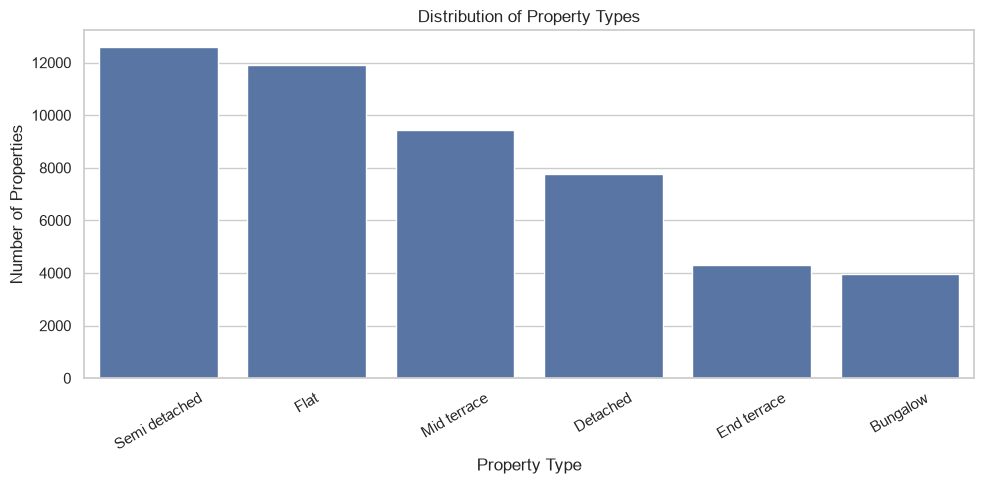

In [38]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="PROP_TYPE",
    order=df_clean["PROP_TYPE"].value_counts().index
)

plt.title("Distribution of Property Types")
plt.xlabel("Property Type")
plt.ylabel("Number of Properties")
plt.xticks(rotation=30)
plt.tight_layout()

save_fig("property_type_distribution")
plt.show()

Semi-detached properties are the most represented property type, followed by flats and mid-terrace houses. Bungalows and end-terrace properties are less represented in the dataset.

Figure saved to figures\gas_consumption_distribution_2024.png


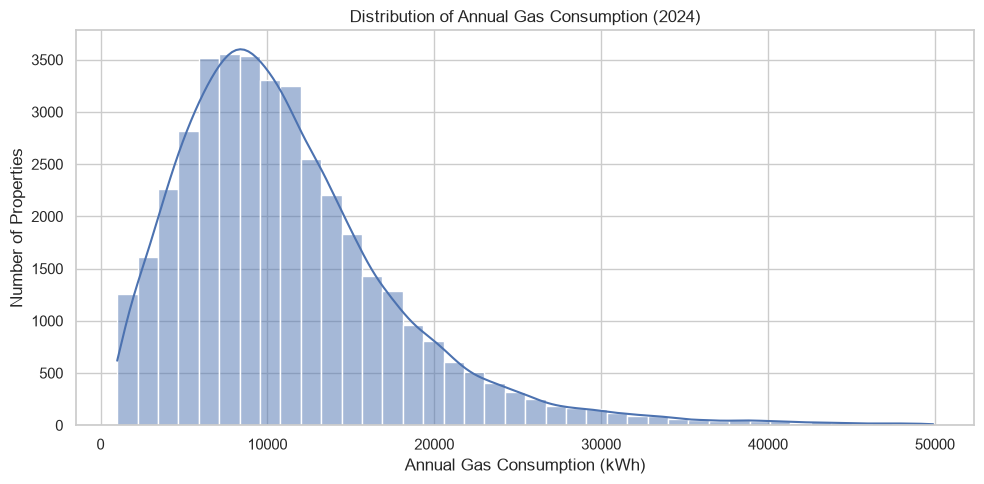

In [39]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="Gcons2024",
    bins=40,
    kde=True
)

plt.title("Distribution of Annual Gas Consumption (2024)")
plt.xlabel("Annual Gas Consumption (kWh)")
plt.ylabel("Number of Properties")
plt.tight_layout()

save_fig("gas_consumption_distribution_2024")
plt.show()

Annual gas consumption in 2024 is right-skewed, with most recorded values concentrated at lower consumption levels and fewer properties showing high consumption. The distribution indicates substantial variation in gas use across the dataset

# Distribution of Annual Electricity Consumption (2024)

Figure saved to figures\electricity_consumption_distribution_2024.png


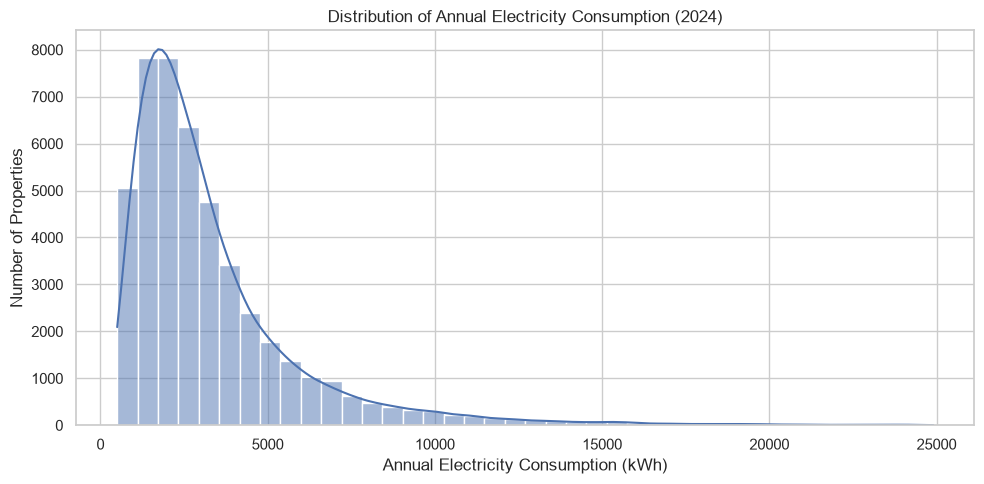

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="Econs2024",
    bins=40,
    kde=True
)

plt.title("Distribution of Annual Electricity Consumption (2024)")
plt.xlabel("Annual Electricity Consumption (kWh)")
plt.ylabel("Number of Properties")
plt.tight_layout()

save_fig("electricity_consumption_distribution_2024")
plt.show()

Annual electricity consumption in 2024 is right-skewed, with most recorded values concentrated at lower consumption levels and fewer properties showing high consumption. This indicates substantial variation in electricity use across the sampled properties.

## Bivariate Analysis

## How does annual gas consumption vary across property types?

Figure saved to figures\gas_consumption_by_property_type.png


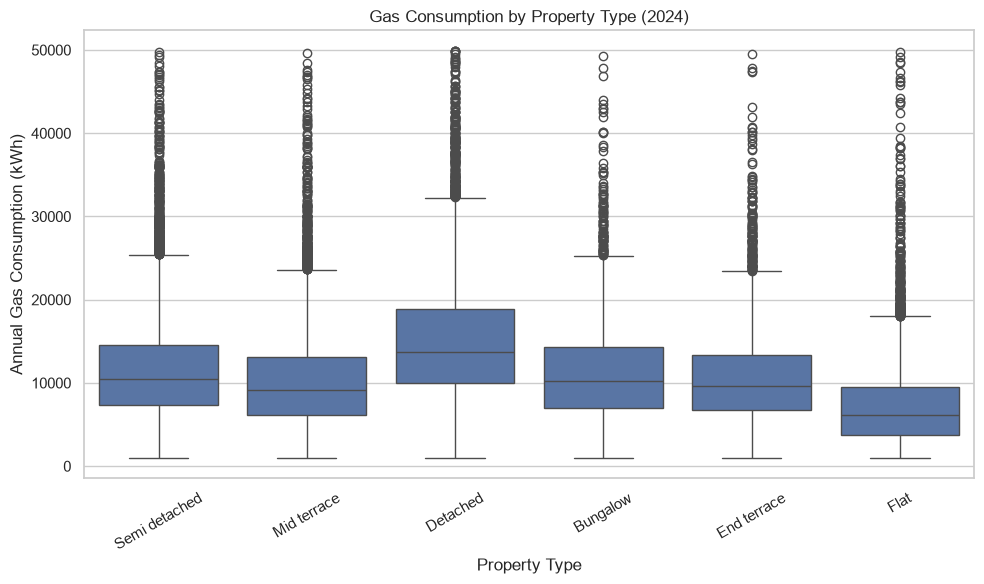

In [41]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="PROP_TYPE",
    y="Gcons2024"
)

plt.title("Gas Consumption by Property Type (2024)")
plt.xlabel("Property Type")
plt.ylabel("Annual Gas Consumption (kWh)")
plt.xticks(rotation=30)
plt.tight_layout()

save_fig("gas_consumption_by_property_type")
plt.show()

Detached properties have the highest median annual gas consumption in 2024, while flats have the lowest.  
Detached properties also show a relatively wide distribution of consumption values.  

These differences may relate to building form and exposed envelope area. Floor area, property age, insulation, heating systems, and occupancy may also influence consumption. 

# Does annual gas consumption vary across property age bands?

Figure saved to figures\gas_consumption_by_property_age.png


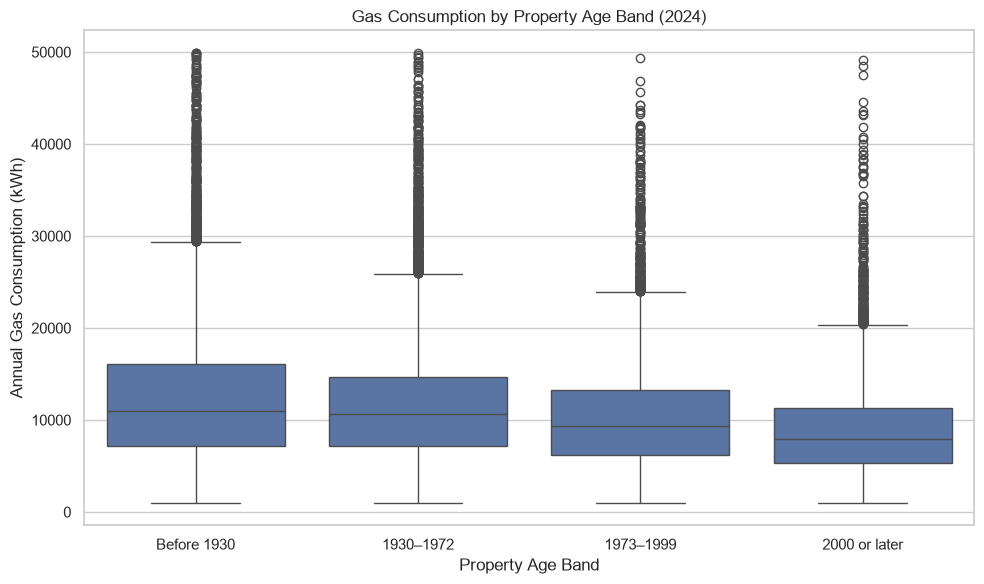

In [42]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="PROP_AGE_BAND",
    y="Gcons2024"
)

plt.title("Gas Consumption by Property Age Band (2024)")
plt.xlabel("Property Age Band")
plt.ylabel("Annual Gas Consumption (kWh)")
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=[
        "Before 1930",
        "1930–1972",
        "1973–1999",
        "2000 or later"
    ]
)

plt.tight_layout()
save_fig("gas_consumption_by_property_age")
plt.show()

The median annual gas consumption generally decreases across the property age bands, from properties built before 1930 to those built in 2000 or later. Older properties also show a broad distribution of consumption values.

# How does property floor area relate to annual gas consumption?

Figure saved to figures\gas_consumption_by_floor_area.png


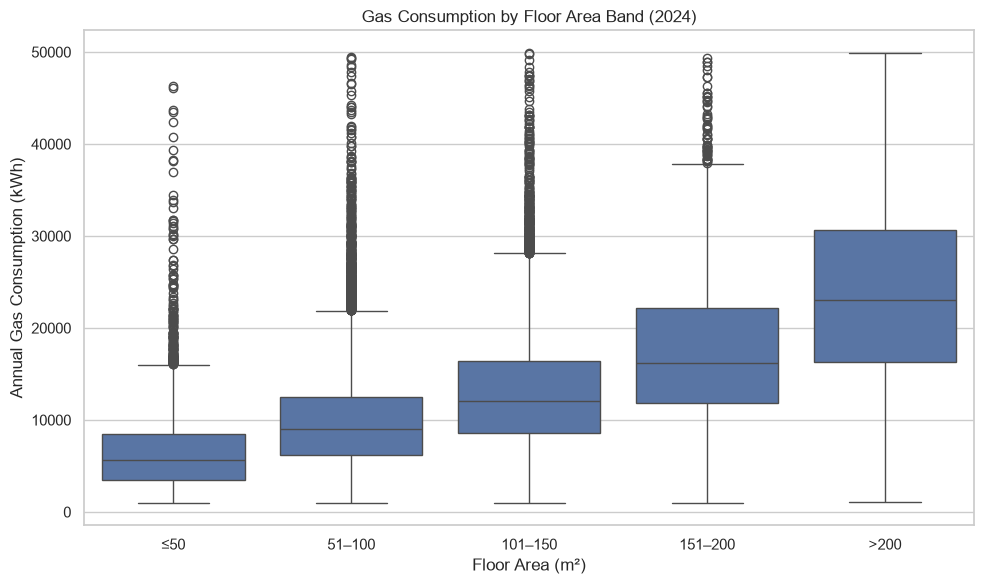

In [43]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="FLOOR_AREA_BAND",
    y="Gcons2024"
)

plt.title("Gas Consumption by Floor Area Band (2024)")
plt.xlabel("Floor Area (m²)")
plt.ylabel("Annual Gas Consumption (kWh)")

plt.xticks(
    ticks=[0, 1, 2, 3, 4],
    labels=[
        "≤50",
        "51–100",
        "101–150",
        "151–200",
        ">200"
    ]
)

plt.tight_layout()
save_fig("gas_consumption_by_floor_area")
plt.show()

Median annual gas consumption increases across the floor-area bands, from approximately 5,500 kWh for properties of 50 m² or less to approximately 23,000 kWh for properties larger than 200 m². The spread of consumption also tends to increase with floor area.

# Grouped Analysis

# Gas Consumption by Property Type

This analysis compares the number of properties and their median and mean annual gas consumption across property types.

In [44]:
gas_by_type = (
    df_clean.groupby("PROP_TYPE")["Gcons2024"]
    .agg(["count", "median", "mean"])
    .round(0)
    .sort_values("median", ascending=False)
)

gas_by_type

,count,median,mean
PROP_TYPE,,,
Detached,6417,"13,700.00","15,271.00"
Semi detached,11586,"10,500.00","11,635.00"
Bungalow,3311,"10,200.00","11,256.00"
End terrace,3942,"9,600.00","10,715.00"
Mid terrace,8601,"9,200.00","10,274.00"
Flat,5645,"6,200.00","7,458.00"


Detached properties have the highest median annual gas consumption (13,700 kWh), while flats have the lowest (6,200 kWh). For every property type, mean consumption exceeds median consumption, consistent with a right-skewed distribution.

# Correlation analysis

Figure saved to figures\correlation_heatmap_2024.png


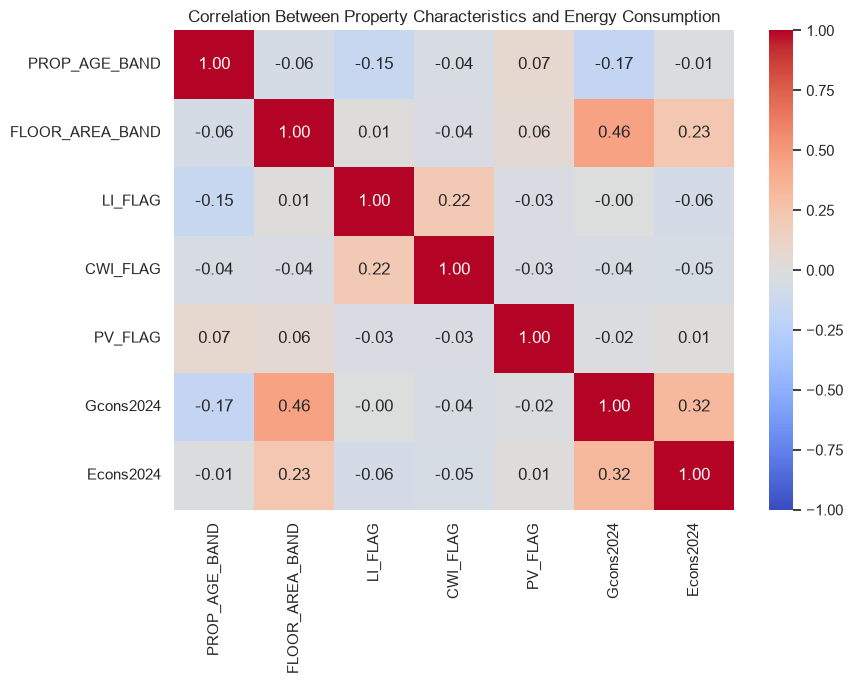

In [45]:
corr_cols = [
    "PROP_AGE_BAND",
    "FLOOR_AREA_BAND",
    "LI_FLAG",
    "CWI_FLAG",
    "PV_FLAG",
    "Gcons2024",
    "Econs2024"
]

corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Property Characteristics and Energy Consumption")
plt.tight_layout()

save_fig("correlation_heatmap_2024")
plt.show()

Floor area band has the strongest observed correlation with gas consumption (r = 0.46), followed by the positive relationship between gas and electricity consumption (r = 0.32).  
 
Floor area band is also positively correlated with electricity consumption (r = 0.23).

Property age band has a weak negative correlation with gas consumption (r = -0.17), consistent with the grouped comparisons.

---

## Conclusions

### Key Findings

- **Property type:** Detached properties had the highest median annual gas consumption in 2024 (13,700 kWh), while flats had the lowest (6,200 kWh).

- **Property age:** Median gas consumption generally decreased across the age bands, from approximately 11,000 kWh for properties built before 1930 to 7,900 kWh for properties built in 2000 or later.

- **Floor area:** Median annual gas consumption increased from approximately 5,500 kWh for properties of 50 m² or less to 23,000 kWh for properties larger than 200 m².

- **Correlation:** Floor-area band had a moderate positive correlation with gas consumption (r = 0.46). Gas and electricity consumption were also positively correlated (r = 0.32).

- **Energy consumption distributions:** Both gas and electricity consumption were right-skewed, indicating that relatively few properties had substantially higher recorded consumption than most properties.

### Limitations and Biases

- **Missing data:** The dataset contains 809,894 missing cells (16.87% of all cells).

- **Reporting thresholds:** Gas consumption below 1,000 kWh or above 50,000 kWh, and electricity consumption below 500 kWh or above 25,000 kWh, are suppressed according to the dataset metadata. Consequently, the observed distributions do not represent the complete range of actual consumption.

- **Sampling bias:** The dataset represents sampled domestic properties in England and Wales. Rare property types, missing key characteristics, and combinations represented by fewer than five properties were filtered during dataset preparation. Results may not generalise to all housing stock or other countries.

- **Limited explanatory variables:** The dataset does not establish the effects of occupancy, indoor temperatures, heating behaviour, or every aspect of building condition. Observed differences cannot be attributed to a single building characteristic.

- **Cleaning decisions:** Two duplicate rows were removed. Missing values and documented validation flags were retained rather than imputed or deleted. This preserves the available information but means that individual analyses may have different sample sizes.

---

### Ready for Modelling

Two potential regression tasks can be developed from this dataset:

**Model 1 — Gas Consumption Prediction**
- Target: `Gcons2024`
- Inputs: `PROP_TYPE`, `PROP_AGE_BAND`, `FLOOR_AREA_BAND`, `CONSERVATORY_FLAG`, `COUNCIL_TAX_BAND`, `IMD_BAND_ENG`, `IMD_BAND_WALES`, `REGION`, `EPC`, `LI_FLAG`, `CWI_FLAG`, `PV_FLAG`.

**Model 2 — Electricity Consumption Prediction**
- Target: `Econs2024`
- Inputs: `PROP_TYPE`, `PROP_AGE_BAND`, `FLOOR_AREA_BAND`, `CONSERVATORY_FLAG`, `COUNCIL_TAX_BAND`, `IMD_BAND_ENG`, `IMD_BAND_WALES`, `REGION`, `EPC`, `LI_FLAG`, `CWI_FLAG`, `PV_FLAG`.

Figure saved to figures\average_energy_by_building_type.png


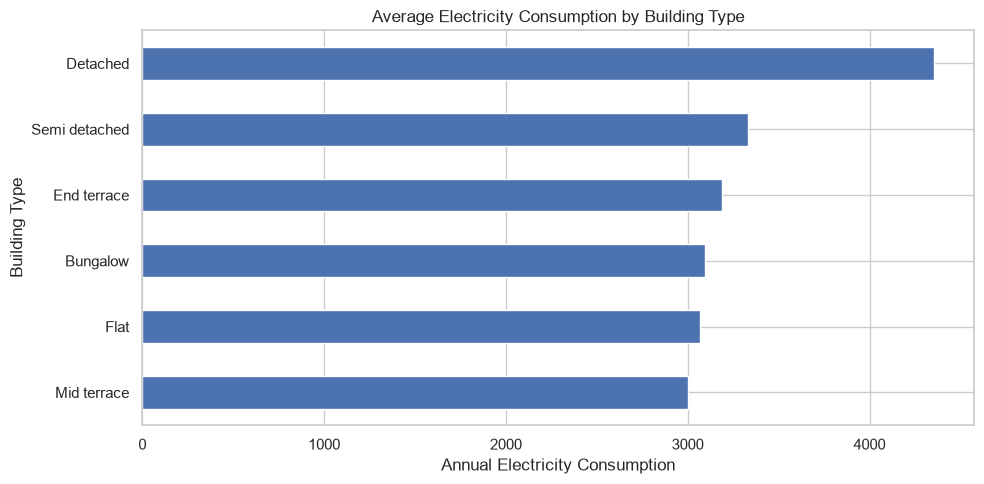

In [46]:
energy_by_type = (
    df_clean.groupby("PROP_TYPE")["Econs2024"]
    .mean()
    .sort_values()
)

energy_by_type.plot(kind="barh", figsize=(10, 5))

plt.title("Average Electricity Consumption by Building Type")
plt.xlabel("Annual Electricity Consumption")
plt.ylabel("Building Type")
plt.tight_layout()
save_fig("average_energy_by_building_type")
plt.show()

Figure saved to figures\epc_distribution.png


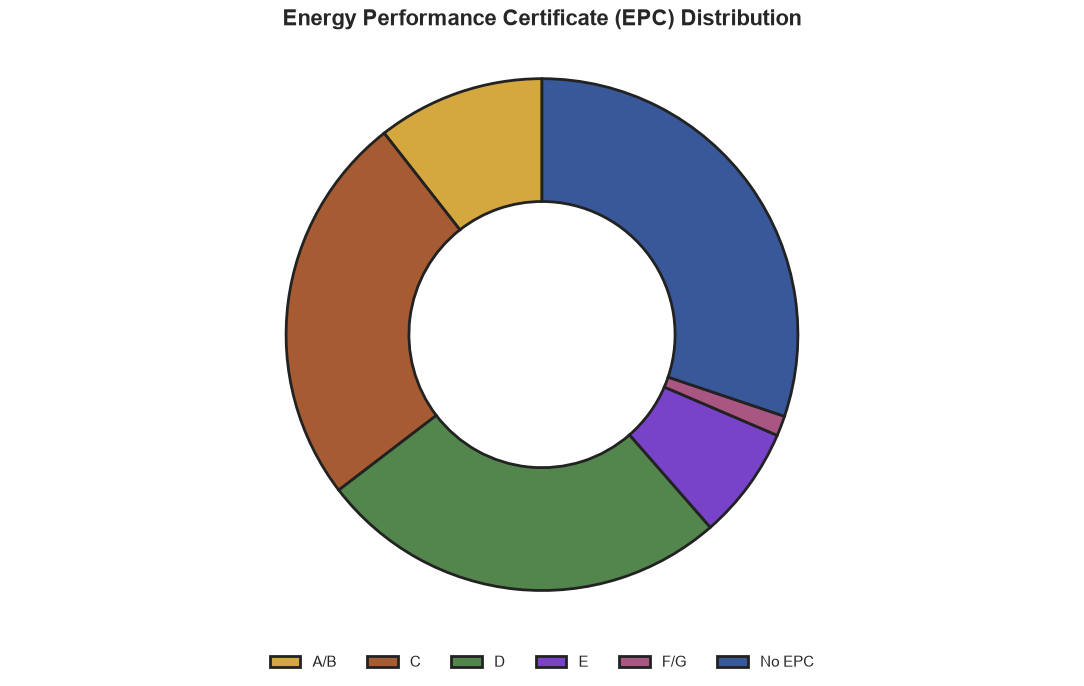

,EPC category,Properties,Percentage
0,No recorded EPC,15086,30.17
1,D,13015,26.03
2,C,12408,24.82
3,A/B,5289,10.58
4,E,3565,7.13
5,F/G,635,1.27


In [47]:
# 1. Prepare EPC data
epc = df_clean["EPC"].copy()

# Convert EPC codes into categories
epc = epc.fillna("No EPC").astype(str).str.strip().str.upper()

epc = epc.replace({
    "NAN": "No EPC",
    "NONE": "No EPC",
    "": "No EPC"
})

# Combine A and B, and F and G
epc = epc.replace({
    "A": "A/B",
    "B": "A/B",
    "F": "F/G",
    "G": "F/G",
    "NO EPC": "No EPC"
})

# 2. Count properties
categories = ["A/B", "C", "D", "E", "F/G", "No EPC"]

epc_counts = epc.value_counts().reindex(
    categories, fill_value=0
)

# 3. Define chart colors
colors = [
    "#D4A83F",  # A/B - Gold
    "#A65B32",  # C - Brown
    "#53864D",  # D - Green
    "#7843C9",  # E - Purple
    "#A95782",  # F/G - Pink
    "#38589A"   # No EPC - Blue
]

# 4. Create donut chart
fig, ax = plt.subplots(figsize=(11, 7))

wedges, texts = ax.pie(
    epc_counts.values,
    colors=colors,
    startangle=90,
    wedgeprops={
        "width": 0.48,
        "edgecolor": "#222222",
        "linewidth": 2
    }
)

ax.set_title(
    "Energy Performance Certificate (EPC) Distribution",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.legend(
    wedges,
    categories,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=6,
    frameon=False
)

ax.axis("equal")

plt.tight_layout()
save_fig("epc_distribution")
plt.show()

# 5. Create EPC summary table
epc_table = pd.DataFrame({
    "EPC category": [
        "No recorded EPC", "D", "C", "A/B", "E", "F/G"
    ],
    "Properties": [
        epc_counts["No EPC"],
        epc_counts["D"],
        epc_counts["C"],
        epc_counts["A/B"],
        epc_counts["E"],
        epc_counts["F/G"]
    ]
})

epc_table["Percentage"] = (
    epc_table["Properties"] / len(df_clean) * 100
).round(2)

display(epc_table)

Figure saved to figures\average_annual_gas_consumption.png


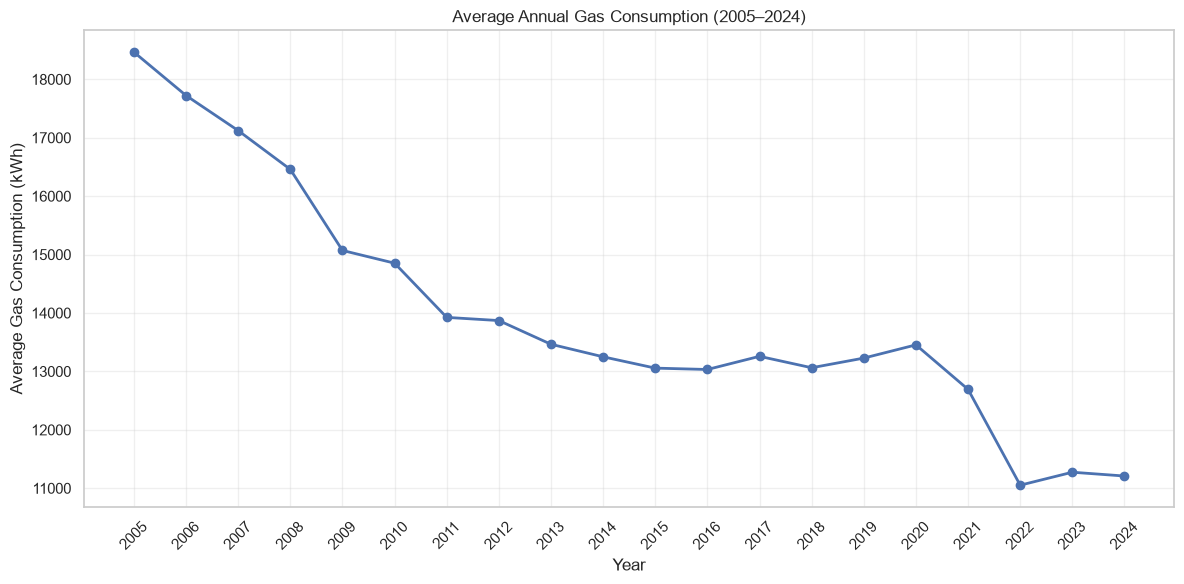

In [48]:
# Years from 2005 to 2024
years = list(range(2005, 2025))

# Column names
gas_columns = [f"Gcons{year}" for year in years]

# Calculate average gas consumption
gas_average = (
    df_clean[gas_columns]
    .apply(pd.to_numeric, errors="coerce")
    .mean()
)

# Create line graph
plt.figure(figsize=(12, 6))

plt.plot(
    years,
    gas_average.values,
    marker="o",
    linewidth=2
)

plt.title("Average Annual Gas Consumption (2005–2024)")
plt.xlabel("Year")
plt.ylabel("Average Gas Consumption (kWh)")
plt.xticks(years, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("average_annual_gas_consumption")
plt.show()

Figure saved to figures\average_annual_electricity_consumption.png


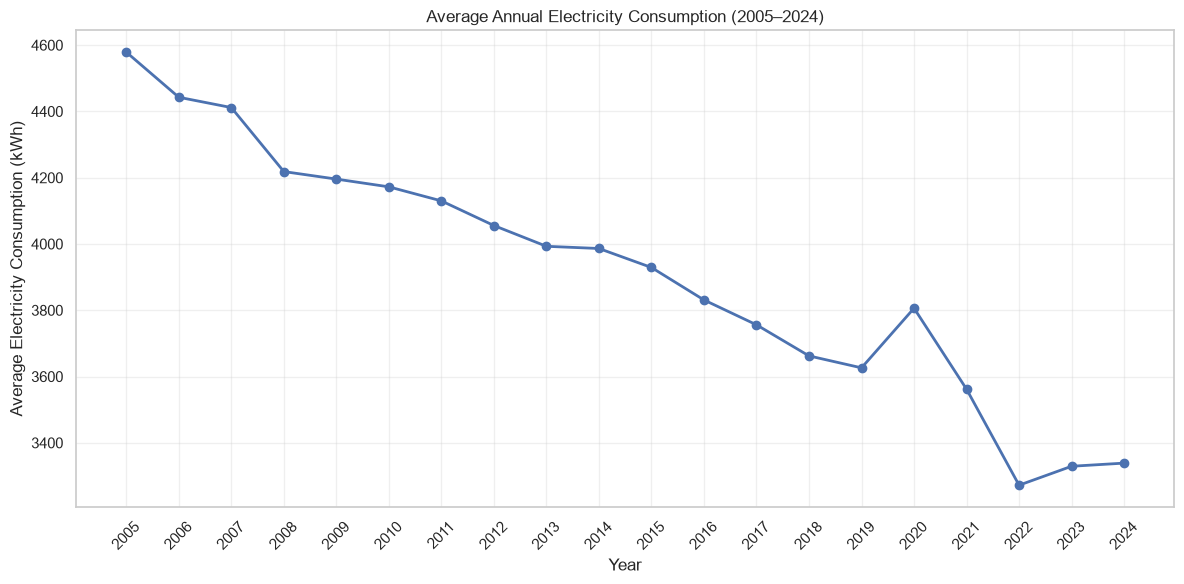

In [49]:
# Column names
electricity_columns = [f"Econs{year}" for year in years]

# Calculate average electricity consumption
electricity_average = (
    df_clean[electricity_columns]
    .apply(pd.to_numeric, errors="coerce")
    .mean()
)

# Create line graph
plt.figure(figsize=(12, 6))

plt.plot(
    years,
    electricity_average.values,
    marker="o",
    linewidth=2
)

plt.title("Average Annual Electricity Consumption (2005–2024)")
plt.xlabel("Year")
plt.ylabel("Average Electricity Consumption (kWh)")
plt.xticks(years, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("average_annual_electricity_consumption")
plt.show()

Figure saved to figures\gas_vs_electricity_consumption_trends.png


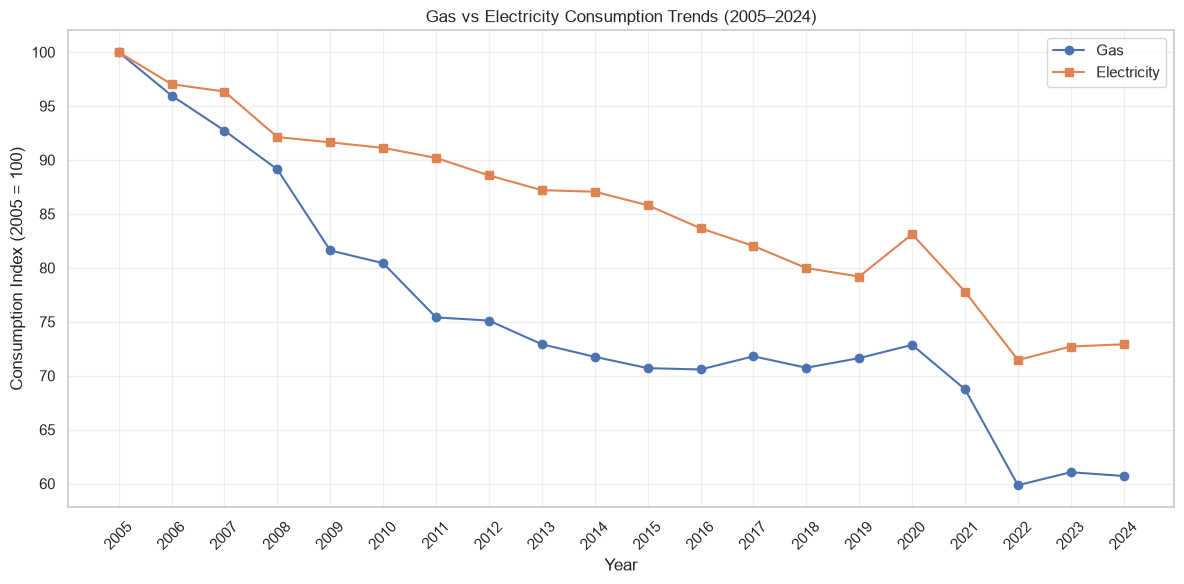

In [51]:
gas_index = gas_average.values / gas_average.iloc[0] * 100
electricity_index = (
    electricity_average.values / electricity_average.iloc[0] * 100
)

plt.figure(figsize=(12, 6))

plt.plot(years, gas_index, marker="o", label="Gas")
plt.plot(years, electricity_index, marker="s", label="Electricity")

plt.title("Gas vs Electricity Consumption Trends (2005–2024)")
plt.xlabel("Year")
plt.ylabel("Consumption Index (2005 = 100)")
plt.xticks(years, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("gas_vs_electricity_consumption_trends")
plt.show()

In [52]:
energy_summary = pd.DataFrame({
    "Year": years,
    "Average Gas Consumption": gas_average.values,
    "Average Electricity Consumption": electricity_average.values
})

display(energy_summary.round(2))

,Year,Average Gas Consumption,Average Electricity Consumption
0,2005,"18,465.19","4,578.83"
1,2006,"17,722.09","4,442.63"
2,2007,"17,121.84","4,411.57"
3,2008,"16,457.95","4,218.39"
4,2009,"15,070.04","4,195.71"
5,2010,"14,852.24","4,172.32"
6,2011,"13,924.31","4,129.92"
7,2012,"13,869.94","4,055.57"
8,2013,"13,464.25","3,992.93"
9,2014,"13,249.55","3,986.28"
